In [1]:
__author__ = "Pablo González Ferro"

# Proyecto AA. Preprocesamiento de los datos

Este notebook va después del EDA (`EDA.ipynb`) y cubre lo que pide el primer punto de control de la S09: tener implementado el código para preprocesar los datos y una versión preprocesada con la que empezar a modelar.

Aquí aplico las decisiones que salieron del EDA, usando solo lo visto en la U1-S02:

1. **Limpieza** (no aprende nada de los datos): quitar columnas personales y de gestión, unificar las binarias a 0/1 y pasar las ordinales a números.
2. **Separación en train y test** de cada línea supervisada, **antes** de ajustar nada, para no tener fuga de información.
3. **Imputación** de los nulos con `SimpleImputer`: mediana para las numéricas y moda para binarias y ordinales.
4. **Escalado** con `RobustScaler` de las columnas que no son binarias, por los atípicos del IMC.
5. **Guardado** de los datos preprocesados y de los imputadores y el escalador como artefactos, porque, como se vio en la U1-S02, hay que aplicar exactamente lo mismo a los datos nuevos en tiempo de inferencia.

Todo esto lo hago para las tres líneas de trabajo, porque cada una necesita su propio preprocesamiento: cambian la variable objetivo, las columnas de entrada y cómo se reparten train y test.

Las funciones de limpieza y preprocesamiento están en `preprocesado.py` y no en el propio notebook, porque luego las necesitaremos también en la API. Así me aseguro de que los datos nuevos pasan exactamente por los mismos pasos que los de entrenamiento.

## 0. Preparación

In [2]:
# Manejo de dataframes y operaciones numéricas
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Para separar train y test, como en la PLD4 y la PLD5
from sklearn.model_selection import train_test_split

# Para guardar los imputadores y el escalador como artefactos en un archivo
import joblib

# Para crear las carpetas de salida
from pathlib import Path

# Mis funciones de limpieza y preprocesamiento
import preprocesado as pp

sns.set_theme(style="whitegrid")

# Ruta al CSV original del proyecto
RUTA_DATOS = "proy_diabetes_dev.csv"

# Semilla para que la separación train/test salga siempre igual
SEMILLA = 42

# Proporción de datos que se reserva para test
TAMANO_TEST = 0.2

# Carpetas donde se guardan los datos preprocesados y los artefactos
CARPETA_DATOS = Path("datos_preprocesados")
CARPETA_ARTEFACTOS = Path("artefactos")
CARPETA_DATOS.mkdir(exist_ok=True)
CARPETA_ARTEFACTOS.mkdir(exist_ok=True)

## 1. Carga y limpieza

Cargo el CSV original como texto, igual que en el EDA, y le aplico `pp.limpiar()`, que hace exactamente la misma limpieza que el apartado 1.2 del EDA. Para asegurarme compruebo que el resultado es idéntico al `proy_diabetes_limpio.csv` que exporta el EDA.

In [3]:
# Cargo el CSV tal cual, todo como texto
crudo = pd.read_csv(RUTA_DATOS, dtype=str, keep_default_na=False)

# Aplico la limpieza
df = pp.limpiar(crudo)
print("Forma tras la limpieza:", df.shape)

# Compruebo que da lo mismo que la limpieza del EDA
limpio_eda = pd.read_csv("proy_diabetes_limpio.csv", index_col=0)
assert list(df.columns) == list(limpio_eda.columns), "Las columnas no coinciden con las del EDA"
assert df.astype(float).equals(limpio_eda.astype(float)), "La limpieza no coincide con la del EDA"
print("La limpieza coincide con la del EDA")

df.head()

Forma tras la limpieza: (12750, 20)
La limpieza coincide con la del EDA


,presion_alta,colesterol_alto,chequeo_colesterol_5a,imc,fumador,ictus,enfermedad_cardiaca,actividad_fisica,consume_fruta,consume_verdura,consumo_alcohol_alto,salud_general,dias_salud_mental_mala,dias_salud_fisica_mala,dificultad_caminar,sexo,grupo_edad,nivel_educativo,nivel_ingresos,diabetes
id_paciente_proy,,,,,,,,,,,,,,,,,,,,
90,1,1,1,NaN,0,0,0,1,1,1,0,<NA>,NaN,0,0,1,8,4,<NA>,0
2443,1,1,1,41.0,0,0,0,0,1,1,0,3,0.0,0,1,0,13,4,2,1
11061,1,1,1,30.0,0,0,0,1,0,1,0,2,0.0,0,0,1,9,4,6,1
4777,1,1,1,36.0,1,0,0,0,1,1,0,3,0.0,2,1,0,9,6,8,1
14534,0,1,1,30.0,0,0,0,1,0,0,0,2,5.0,30,1,1,7,4,7,0


In [4]:
# Nulos que quedan después de limpiar: son los que hay que imputar
nulos = df.isna().sum()
nulos[nulos > 0]

imc                       397
fumador                   376
actividad_fisica          376
consume_fruta             376
salud_general             267
dias_salud_mental_mala    397
dificultad_caminar        376
nivel_ingresos            657
dtype: int64

Quedan 20 columnas, todas ya numéricas, y los nulos de las 8 columnas que vimos en el EDA. A partir de aquí cada línea de trabajo sigue su camino.

### Decisión sobre la otra variable objetivo

En el EDA comenté que es válido usar un objetivo como entrada del otro, porque el enunciado dice que se predice "a partir del resto de indicadores recogidos en la encuesta". Por eso, de momento:

- En **clasificación** uso `dias_salud_fisica_mala` como variable de entrada.
- En **regresión** uso `diabetes` como variable de entrada.

Lo dejo en una constante porque es una decisión que habrá que revisar con el contrato de la API: si el profesor no manda la otra variable objetivo en las instancias de cada línea, habrá que quitarla y volver a ejecutar el notebook.

In [5]:
# Cambiar a False si el contrato de la API no incluye la otra variable objetivo en las instancias
USAR_OTRO_OBJETIVO = True

### Funciones de comprobación

Para no repetir código, defino una función que comprueba que el preprocesamiento ha salido bien en cualquier línea: que no quedan nulos, que las binarias siguen siendo 0/1 y que la imputación se ha hecho con los valores del train y no con los de todo el conjunto.

In [6]:
def comprueba_preprocesado(prep, X_train, X_train_prep, X_test_prep):
    """Comprobaciones básicas del preprocesamiento de una línea de trabajo."""
    # No quedan nulos ni en train ni en test
    assert X_train_prep.isna().sum().sum() == 0, "Quedan nulos en el train"
    assert X_test_prep.isna().sum().sum() == 0, "Quedan nulos en el test"

    # Las binarias siguen siendo 0/1 (no se escalan)
    binarias = [c for c in X_train_prep.columns if c not in prep["cols_escalar"]]
    assert X_train_prep[binarias].isin([0, 1]).all().all(), "Alguna binaria tiene valores distintos de 0/1"

    # Las medianas del imputador son las del train (y no las de todo el dataset)
    if prep["cols_num"]:
        medianas_train = X_train[prep["cols_num"]].astype(float).median().values
        assert np.allclose(prep["imp_num"].statistics_, medianas_train), "El imputador no usa las medianas del train"

    print("Comprobaciones superadas")
    print("  mediana usada para imputar:", dict(zip(prep["cols_num"], prep["imp_num"].statistics_)) if prep["cols_num"] else "-")

## 2. Línea de clasificación: `diabetes`

### 2.1 Variables de entrada y objetivo

In [7]:
# La salida es la diabetes y la entrada es todo lo demás
y_clf = df[pp.OBJ_CLF].astype(int)
X_clf = df.drop(columns=[pp.OBJ_CLF])

# Si se decide no usar la otra variable objetivo, se quita de las entradas
if not USAR_OTRO_OBJETIVO:
    X_clf = X_clf.drop(columns=[pp.OBJ_REG])

print("Entradas:", X_clf.shape[1], "columnas ->", list(X_clf.columns))

Entradas: 19 columnas -> ['presion_alta', 'colesterol_alto', 'chequeo_colesterol_5a', 'imc', 'fumador', 'ictus', 'enfermedad_cardiaca', 'actividad_fisica', 'consume_fruta', 'consume_verdura', 'consumo_alcohol_alto', 'salud_general', 'dias_salud_mental_mala', 'dias_salud_fisica_mala', 'dificultad_caminar', 'sexo', 'grupo_edad', 'nivel_educativo', 'nivel_ingresos']


### 2.2 Separación en train y test

Separo **antes** de ajustar ningún imputador ni escalador, porque como se vio en la U1-S02, ajustarlos con todo el conjunto (incluido el test) es fuga de información. Uso `stratify=y` como en la PLD5, para que el 33 % de diabéticos se mantenga en los dos conjuntos.

In [8]:
# 80 % train, 20 % test, estratificando por la diabetes
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=TAMANO_TEST, stratify=y_clf, random_state=SEMILLA
)

# Compruebo que la proporción de diabéticos es la misma en los dos lados
pd.DataFrame({
    "n": [len(y_clf_train), len(y_clf_test)],
    "% diabetes": [y_clf_train.mean() * 100, y_clf_test.mean() * 100],
}, index=["train", "test"]).round(2)

,n,% diabetes
train,10200,33.24
test,2550,33.25


### 2.3 Imputación y escalado

Ajusto el preprocesador **solo con el train** y después lo aplico a los dos conjuntos. Guardo dos versiones de los datos:

- **Sin escalar** (solo imputados): para los modelos basados en árboles, que como se vio en la U1-S02 no necesitan escalado. Además se leen más fácil, porque los valores siguen siendo los originales.
- **Escalados**: para los modelos sensibles a la escala, como la regresión logística, KNN o SVM.

In [9]:
# Ajusto imputadores y escalador con el train
prep_clf = pp.ajustar_preprocesador(X_clf_train)

# Versión sin escalar (solo imputada)
X_clf_train_imp = pp.aplicar_preprocesador(prep_clf, X_clf_train, escalar=False)
X_clf_test_imp = pp.aplicar_preprocesador(prep_clf, X_clf_test, escalar=False)

# Versión escalada
X_clf_train_esc = pp.aplicar_preprocesador(prep_clf, X_clf_train)
X_clf_test_esc = pp.aplicar_preprocesador(prep_clf, X_clf_test)

print("Columnas que se imputan con la mediana:", prep_clf["cols_num"])
print("Columnas que se escalan con RobustScaler:", prep_clf["cols_escalar"])
comprueba_preprocesado(prep_clf, X_clf_train, X_clf_train_esc, X_clf_test_esc)

Columnas que se imputan con la mediana: ['imc', 'dias_salud_mental_mala', 'dias_salud_fisica_mala']
Columnas que se escalan con RobustScaler: ['imc', 'salud_general', 'dias_salud_mental_mala', 'dias_salud_fisica_mala', 'grupo_edad', 'nivel_educativo', 'nivel_ingresos']
Comprobaciones superadas
  mediana usada para imputar: {'imc': np.float64(28.0), 'dias_salud_mental_mala': np.float64(0.0), 'dias_salud_fisica_mala': np.float64(0.0)}


In [10]:
# Antes y después del escalado para las columnas escaladas: la mediana pasa a 0
pd.DataFrame({
    "mediana_antes": X_clf_train_imp[prep_clf["cols_escalar"]].median(),
    "IQR_antes": X_clf_train_imp[prep_clf["cols_escalar"]].quantile(0.75) - X_clf_train_imp[prep_clf["cols_escalar"]].quantile(0.25),
    "mediana_despues": X_clf_train_esc[prep_clf["cols_escalar"]].median(),
    "IQR_despues": X_clf_train_esc[prep_clf["cols_escalar"]].quantile(0.75) - X_clf_train_esc[prep_clf["cols_escalar"]].quantile(0.25),
}).round(2)

,mediana_antes,IQR_antes,mediana_despues,IQR_despues
imc,28.0,7.0,0.0,1.0
salud_general,3.0,1.0,0.0,1.0
dias_salud_mental_mala,0.0,2.0,0.0,1.0
dias_salud_fisica_mala,0.0,4.0,0.0,1.0
grupo_edad,9.0,4.0,0.0,1.0
nivel_educativo,5.0,2.0,0.0,1.0
nivel_ingresos,7.0,3.0,0.0,1.0


Tras el `RobustScaler` todas las columnas escaladas tienen mediana 0 y un rango intercuartílico de 1, así que ya están en una escala comparable. Sin embargo, hay que vigilar los conteos de días: como la mayoría son ceros, su IQR original es muy pequeño (2 días en salud mental y 4 en física), y un paciente con 30 días pasa a valer 15 y 7,5 respectivamente una vez escalado, muy lejos del resto. Es algo a tener en cuenta con los modelos basados en distancias como KNN.

In [11]:
# Guardo los datos (entradas + objetivo) en CSV, conservando el id como índice
carpeta = CARPETA_DATOS / "clasificacion"
carpeta.mkdir(exist_ok=True)
X_clf_train_imp.assign(**{pp.OBJ_CLF: y_clf_train}).to_csv(carpeta / "train.csv")
X_clf_test_imp.assign(**{pp.OBJ_CLF: y_clf_test}).to_csv(carpeta / "test.csv")
X_clf_train_esc.assign(**{pp.OBJ_CLF: y_clf_train}).to_csv(carpeta / "train_escalado.csv")
X_clf_test_esc.assign(**{pp.OBJ_CLF: y_clf_test}).to_csv(carpeta / "test_escalado.csv")

# Y el preprocesador ajustado como artefacto
joblib.dump(prep_clf, CARPETA_ARTEFACTOS / "preprocesador_clasificacion.joblib")
print("Guardados los datos en", carpeta, "y el artefacto en", CARPETA_ARTEFACTOS)

Guardados los datos en datos_preprocesados\clasificacion y el artefacto en artefactos


## 3. Línea de regresión: `dias_salud_fisica_mala`

### 3.1 Variables de entrada y objetivo

In [12]:
# La salida son los días de mala salud física y la entrada todo lo demás
y_reg = df[pp.OBJ_REG]
X_reg = df.drop(columns=[pp.OBJ_REG])

if not USAR_OTRO_OBJETIVO:
    X_reg = X_reg.drop(columns=[pp.OBJ_CLF])

print("Entradas:", X_reg.shape[1], "columnas ->", list(X_reg.columns))

Entradas: 19 columnas -> ['presion_alta', 'colesterol_alto', 'chequeo_colesterol_5a', 'imc', 'fumador', 'ictus', 'enfermedad_cardiaca', 'actividad_fisica', 'consume_fruta', 'consume_verdura', 'consumo_alcohol_alto', 'salud_general', 'dias_salud_mental_mala', 'dificultad_caminar', 'sexo', 'grupo_edad', 'nivel_educativo', 'nivel_ingresos', 'diabetes']


### 3.2 Separación en train y test

`stratify` necesita una variable categórica, y los días van de 0 a 30. Como propuse en el EDA, estratifico por **tramos** (0, 1-7, 8-14, 15-29 y 30), para que el pico de ceros y el de treintas tengan el mismo peso en train y en test.

In [13]:
# Tramos de la variable objetivo, solo para estratificar (no se usan como variable)
tramos_reg = pd.cut(y_reg, [-1, 0, 7, 14, 29, 30], labels=["0", "1-7", "8-14", "15-29", "30"])

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=TAMANO_TEST, stratify=tramos_reg, random_state=SEMILLA
)

# Compruebo que cada tramo pesa lo mismo en train y en test
pd.DataFrame({
    "train_%": tramos_reg.loc[y_reg_train.index].value_counts(normalize=True).sort_index() * 100,
    "test_%": tramos_reg.loc[y_reg_test.index].value_counts(normalize=True).sort_index() * 100,
}).round(2)

,train_%,test_%
dias_salud_fisica_mala,,
0,60.33,60.31
1-7,20.54,20.55
8-14,4.28,4.27
15-29,5.50,5.53
30,9.34,9.33


In [14]:
# Lo mismo que en clasificación: ajusto con el train y aplico a los dos
prep_reg = pp.ajustar_preprocesador(X_reg_train)

X_reg_train_imp = pp.aplicar_preprocesador(prep_reg, X_reg_train, escalar=False)
X_reg_test_imp = pp.aplicar_preprocesador(prep_reg, X_reg_test, escalar=False)
X_reg_train_esc = pp.aplicar_preprocesador(prep_reg, X_reg_train)
X_reg_test_esc = pp.aplicar_preprocesador(prep_reg, X_reg_test)

print("Columnas que se imputan con la mediana:", prep_reg["cols_num"])
print("Columnas que se escalan con RobustScaler:", prep_reg["cols_escalar"])
comprueba_preprocesado(prep_reg, X_reg_train, X_reg_train_esc, X_reg_test_esc)

Columnas que se imputan con la mediana: ['imc', 'dias_salud_mental_mala']
Columnas que se escalan con RobustScaler: ['imc', 'salud_general', 'dias_salud_mental_mala', 'grupo_edad', 'nivel_educativo', 'nivel_ingresos']
Comprobaciones superadas
  mediana usada para imputar: {'imc': np.float64(28.0), 'dias_salud_mental_mala': np.float64(0.0)}


In [15]:
# Guardo datos y artefacto
carpeta = CARPETA_DATOS / "regresion"
carpeta.mkdir(exist_ok=True)
X_reg_train_imp.assign(**{pp.OBJ_REG: y_reg_train}).to_csv(carpeta / "train.csv")
X_reg_test_imp.assign(**{pp.OBJ_REG: y_reg_test}).to_csv(carpeta / "test.csv")
X_reg_train_esc.assign(**{pp.OBJ_REG: y_reg_train}).to_csv(carpeta / "train_escalado.csv")
X_reg_test_esc.assign(**{pp.OBJ_REG: y_reg_test}).to_csv(carpeta / "test_escalado.csv")

joblib.dump(prep_reg, CARPETA_ARTEFACTOS / "preprocesador_regresion.joblib")
print("Guardados los datos en", carpeta, "y el artefacto en", CARPETA_ARTEFACTOS)

Guardados los datos en datos_preprocesados\regresion y el artefacto en artefactos


La variable objetivo **no** se escala ni se transforma: el modelo tiene que predecir directamente los días. Lo que sí habrá que hacer al predecir, como se dijo en el EDA, es recortar las predicciones al rango [0, 30].

## 4. Línea de clusterización

Aquí no hay variable objetivo, así que no hace falta separar en train y test: el preprocesador se ajusta con todos los datos.

Como concluí en el EDA, para que los perfiles se puedan explicar en una frase uso un **subconjunto pequeño de variables con sentido clínico**, en vez de las 20. Dejo fuera `diabetes` y `dias_salud_fisica_mala` para usarlas después a la hora de **describir** cada grupo.

En el clustering sí que es obligatorio escalar, porque k-medias se basa en distancias (U1-S02). Si no, el IMC (con valores de 13 a 95) pesaría muchísimo más que las binarias.

In [16]:
# Variables clínicas que propuse en el EDA para definir los perfiles
VARS_CLUSTER = ["grupo_edad", "imc", "presion_alta", "colesterol_alto",
                "salud_general", "actividad_fisica", "dificultad_caminar"]

X_cl = df[VARS_CLUSTER]
print("Nulos en las variables de clustering:")
print(X_cl.isna().sum()[X_cl.isna().sum() > 0])

Nulos en las variables de clustering:
imc                   397
salud_general         267
actividad_fisica      376
dificultad_caminar    376
dtype: int64


Comprobaciones superadas
  mediana usada para imputar: {'imc': np.float64(28.0)}


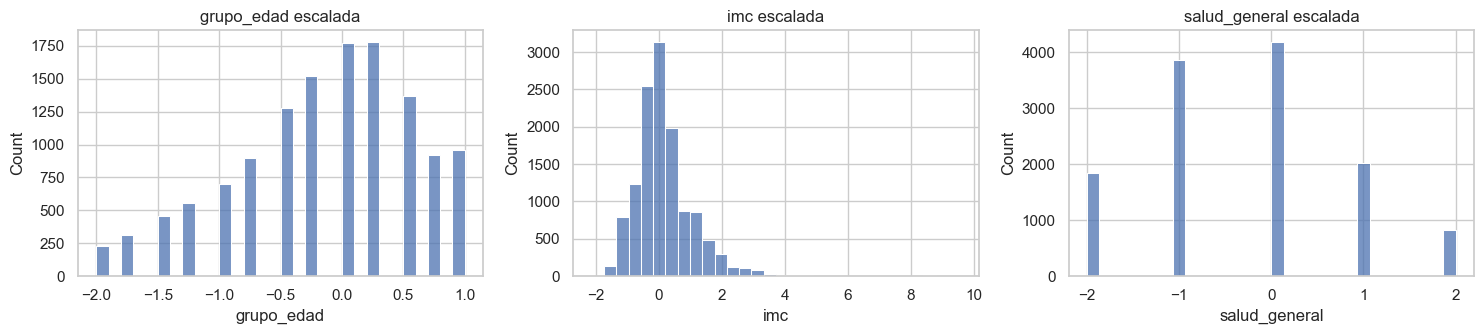

In [17]:
# Ajusto con todos los datos y aplico
prep_cl = pp.ajustar_preprocesador(X_cl)
X_cl_imp = pp.aplicar_preprocesador(prep_cl, X_cl, escalar=False)
X_cl_esc = pp.aplicar_preprocesador(prep_cl, X_cl)

# Aquí no hay test, así que paso el mismo conjunto como train y test a la comprobación
comprueba_preprocesado(prep_cl, X_cl, X_cl_esc, X_cl_esc)

# Distribución de las variables escaladas (las no binarias)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes, prep_cl["cols_escalar"]):
    sns.histplot(X_cl_esc[c], bins=30, ax=ax)
    ax.set_title(f"{c} escalada")
plt.tight_layout()
plt.show()

In [18]:
# Guardo los datos (con los dos objetivos aparte para describir los grupos después) y el artefacto
carpeta = CARPETA_DATOS / "clustering"
carpeta.mkdir(exist_ok=True)
X_cl_imp.to_csv(carpeta / "datos.csv")
X_cl_esc.to_csv(carpeta / "datos_escalado.csv")
df[[pp.OBJ_CLF, pp.OBJ_REG]].to_csv(carpeta / "variables_descriptivas.csv")

joblib.dump(prep_cl, CARPETA_ARTEFACTOS / "preprocesador_clustering.joblib")
print("Guardados los datos en", carpeta, "y el artefacto en", CARPETA_ARTEFACTOS)

Guardados los datos en datos_preprocesados\clustering y el artefacto en artefactos


## 5. Prueba en tiempo de inferencia

Como se vio en la U1-S02, lo importante de guardar los artefactos es poder aplicar a los datos nuevos exactamente el mismo preprocesamiento. Lo simulo como si fuera la API: cargo los artefactos desde disco, cojo unas filas del CSV original **sin las variables objetivo** (que es como llegarán los datos nuevos) y las paso por la limpieza y el preprocesamiento.

Elijo a propósito filas con nulos y con binarias mal escritas (`True`, `1.0`, `SI`...), para comprobar que todo eso se resuelve igual que en el entrenamiento.

In [19]:
# Cargo el artefacto desde el disco, como haría la API
prep_cargado = joblib.load(CARPETA_ARTEFACTOS / "preprocesador_clasificacion.joblib")

# Filas de ejemplo: con algún nulo y con binarias escritas de las formas raras
raras = ~crudo["fumador"].isin(["si", "no", ""])
con_nulo = (crudo == "").any(axis=1)
ejemplo = pd.concat([crudo[raras].head(3), crudo[con_nulo].head(3)])

# Quito la variable objetivo, que no llega en los datos nuevos
nuevos = ejemplo.drop(columns=[pp.OBJ_CLF])
display(nuevos[["id_paciente_proy", "imc", "fumador", "actividad_fisica", "salud_general", "nivel_ingresos"]])

# Limpieza + preprocesamiento, exactamente como en el entrenamiento
X_nuevos = pp.aplicar_preprocesador(prep_cargado, pp.limpiar(nuevos))
assert X_nuevos.isna().sum().sum() == 0, "Quedan nulos en los datos nuevos"
assert list(X_nuevos.columns) == list(X_clf_train_esc.columns), "Las columnas no coinciden con las del train"
X_nuevos

,id_paciente_proy,imc,fumador,actividad_fisica,salud_general,nivel_ingresos
1,2443,41.0,NO,NO,buena,10-15k
6,5682,23.0,False,True,muy buena,25-35k
12,8382,23.0,1.0,1.0,muy buena,>75k
0,90,,no,si,,
7,13387,28.0,,,muy buena,>75k
40,625,25.0,no,si,muy buena,


,presion_alta,colesterol_alto,chequeo_colesterol_5a,imc,fumador,ictus,enfermedad_cardiaca,actividad_fisica,consume_fruta,consume_verdura,consumo_alcohol_alto,salud_general,dias_salud_mental_mala,dias_salud_fisica_mala,dificultad_caminar,sexo,grupo_edad,nivel_educativo,nivel_ingresos
id_paciente_proy,,,,,,,,,,,,,,,,,,,
2443,1.0,1.0,1.0,1.857143,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.00,-0.5,-1.666667
5682,1.0,1.0,1.0,-0.714286,0.0,0.0,0.0,1.0,1.0,1.0,0.0,-1.0,0.0,0.0,0.0,0.0,-0.25,-0.5,-0.666667
8382,1.0,1.0,1.0,-0.714286,1.0,0.0,0.0,1.0,0.0,1.0,1.0,-1.0,1.0,0.0,0.0,0.0,-0.25,0.5,0.333333
90,1.0,1.0,1.0,0.000000,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.25,-0.5,0.333333
13387,0.0,0.0,1.0,0.000000,0.0,0.0,0.0,1.0,1.0,0.0,0.0,-1.0,0.0,0.0,0.0,1.0,-0.50,-0.5,0.333333
625,1.0,1.0,1.0,-0.428571,0.0,0.0,0.0,1.0,0.0,1.0,0.0,-1.0,0.0,0.0,0.0,1.0,-0.25,0.5,0.333333


In [20]:
# Y compruebo que a las filas que ya estaban en train o test les sale lo mismo que en el preprocesamiento original
en_train = X_nuevos.index.intersection(X_clf_train_esc.index)
en_test = X_nuevos.index.intersection(X_clf_test_esc.index)
iguales = (np.allclose(X_nuevos.loc[en_train], X_clf_train_esc.loc[en_train])
           and np.allclose(X_nuevos.loc[en_test], X_clf_test_esc.loc[en_test]))
print(f"Filas comparadas: {len(en_train)} de train y {len(en_test)} de test -> ¿mismo resultado?", iguales)

Filas comparadas: 5 de train y 1 de test -> ¿mismo resultado? True


## 6. Resumen de lo generado

In [21]:
# Listado de todos los archivos que ha generado el notebook, con su tamaño en filas y columnas
filas = []
for ruta in sorted(CARPETA_DATOS.rglob("*.csv")):
    d = pd.read_csv(ruta, index_col=0)
    filas.append({"archivo": str(ruta), "filas": d.shape[0], "columnas": d.shape[1], "nulos": int(d.isna().sum().sum())})
for ruta in sorted(CARPETA_ARTEFACTOS.glob("*.joblib")):
    filas.append({"archivo": str(ruta), "filas": "-", "columnas": "-", "nulos": "-"})
pd.DataFrame(filas)

,archivo,filas,columnas,nulos
0,datos_preprocesados\clasificacion\test.csv,2550,20,0
1,datos_preprocesados\clasificacion\test_escalad...,2550,20,0
2,datos_preprocesados\clasificacion\train.csv,10200,20,0
3,datos_preprocesados\clasificacion\train_escala...,10200,20,0
4,datos_preprocesados\clustering\datos.csv,12750,7,0
5,datos_preprocesados\clustering\datos_escalado.csv,12750,7,0
6,datos_preprocesados\clustering\variables_descr...,12750,2,0
7,datos_preprocesados\regresion\test.csv,2550,20,0
8,datos_preprocesados\regresion\test_escalado.csv,2550,20,0
9,datos_preprocesados\regresion\train.csv,10200,20,0


## 7. Conclusiones

Con este notebook queda cubierto lo que pide la S09: el código de preprocesamiento está implementado (en `preprocesado.py` y aquí) y hay una versión preprocesada de los datos para cada una de las tres líneas, lista para empezar a modelar.

Las decisiones que he tomado, todas sacadas del EDA y de lo visto en la U1-S02, son:

| Paso | Decisión | Por qué |
|---|---|---|
| Limpieza | Quitar columnas personales y de gestión, binarias a 0/1, ordinales a enteros | Defectos registrados en la auditoría del EDA |
| Separación | 80/20, estratificada por `diabetes` en clasificación y por tramos de días en regresión | Mantener la proporción de clases y los dos picos en los dos conjuntos |
| Imputación | Mediana en numéricas y moda en binarias/ordinales, con `SimpleImputer` | Las numéricas son asimétricas y la moda es lo natural para categóricas |
| Escalado | `RobustScaler` en las columnas no binarias; las binarias se quedan en 0/1 | Hay atípicos en el IMC que no se pueden eliminar |
| Ajuste | Imputador y escalador ajustados solo con el train | Evitar la fuga de información |
| Artefactos | Un preprocesador guardado con `joblib` por línea | Aplicar lo mismo a los datos nuevos en la API |

Hay que tener en cuenta varias cosas para los siguientes pasos:

- La imputación simple es la opción más sencilla, pero ignora la relación entre variables (U1-S02). Cuando tengamos un primer modelo, se puede probar a cambiarla por `KNNImputer` o `IterativeImputer` y ver si mejora.
- Lo de usar la otra variable objetivo como entrada (`USAR_OTRO_OBJETIVO`) hay que revisarlo con el contrato de la API, porque si no llega en las instancias los modelos no podrían usarla.
- Los modelos de árboles deberían usar la versión **sin escalar**, que es más fácil de interpretar. Los lineales, KNN y SVM deberían usar la **escalada**.

En conclusión, el preprocesamiento queda separado en dos partes que no se pueden mezclar: la limpieza, que no aprende nada y se puede aplicar a cualquier dato, y la imputación y el escalado, que se ajustan solo con el train y se guardan como un artefacto más del modelo. Si se mezclaran, las métricas del test saldrían más optimistas de lo que son en realidad.